In [8]:
import pandas as pd


In [9]:
df = pd.read_csv("../data/cleaned_data.csv")

print(df.describe())

print("Total Customers:", len(df))

print("Churned Customers:",
      df["Churn"].sum())

print("Churn Rate:",
      df["Churn"].mean() * 100)

           Tenure  MonthlyCharges  TotalCharges  SeniorCitizen       Churn
count  500.000000      500.000000    500.000000     500.000000  500.000000
mean    36.532000      113.636000   4237.882000       0.498000    0.106000
std     20.667057       51.799903   2260.619837       0.500497    0.308146
min      1.000000       20.000000    159.000000       0.000000    0.000000
25%     19.000000       67.000000   2237.250000       0.000000    0.000000
50%     37.000000      115.000000   4182.500000       0.000000    0.000000
75%     54.000000      158.000000   6266.750000       1.000000    0.000000
max     71.000000      199.000000   7992.000000       1.000000    1.000000
Total Customers: 500
Churned Customers: 53
Churn Rate: 10.6


In [10]:
contract_analysis = df.groupby(
    "Contract"
)["Churn"].mean() * 100

print(contract_analysis)

Contract
Month-to-month    20.588235
One year           4.301075
Two year           6.944444
Name: Churn, dtype: float64


In [11]:
payment_analysis = df.groupby(
    "PaymentMethod"
)["Churn"].mean() * 100

print(payment_analysis)

PaymentMethod
Bank Transfer        6.918239
Credit Card         13.483146
Electronic Check    11.042945
Name: Churn, dtype: float64


In [12]:
correlation = df[
    ["Tenure", "MonthlyCharges",
     "TotalCharges", "Churn"]
].corr()

print(correlation)

                  Tenure  MonthlyCharges  TotalCharges     Churn
Tenure          1.000000       -0.059655     -0.005677 -0.509208
MonthlyCharges -0.059655        1.000000     -0.042280  0.107381
TotalCharges   -0.005677       -0.042280      1.000000  0.004250
Churn          -0.509208        0.107381      0.004250  1.000000


In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

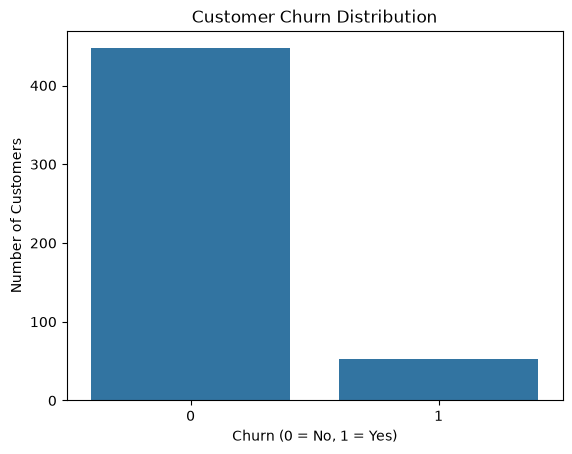

In [16]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.savefig("../visuals/01_churn_distribution.png",
            bbox_inches="tight")
plt.show()

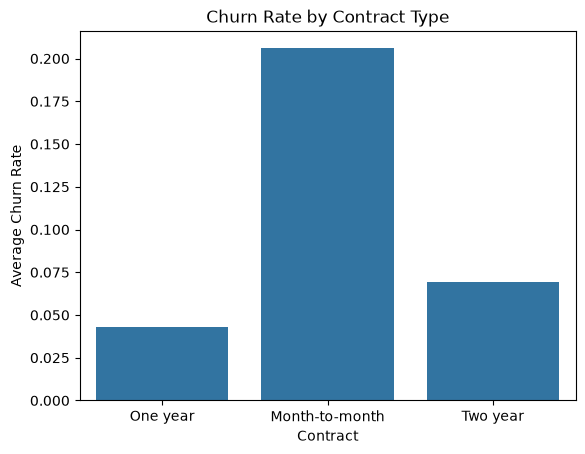

In [17]:
sns.barplot(data=df, x="Contract",
            y="Churn", errorbar=None)
plt.title("Churn Rate by Contract Type")
plt.ylabel("Average Churn Rate")
plt.savefig("../visuals/02_contract_churn.png",
            bbox_inches="tight")
plt.show()

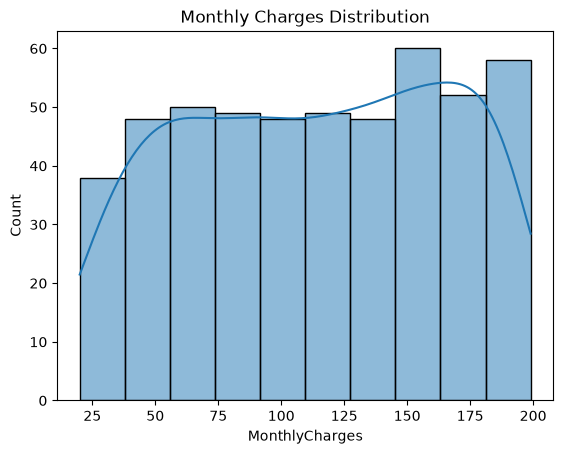

In [18]:
sns.histplot(data=df, x="MonthlyCharges",
             kde=True)
plt.title("Monthly Charges Distribution")
plt.savefig("../visuals/03_monthly_charges.png",
            bbox_inches="tight")
plt.show()

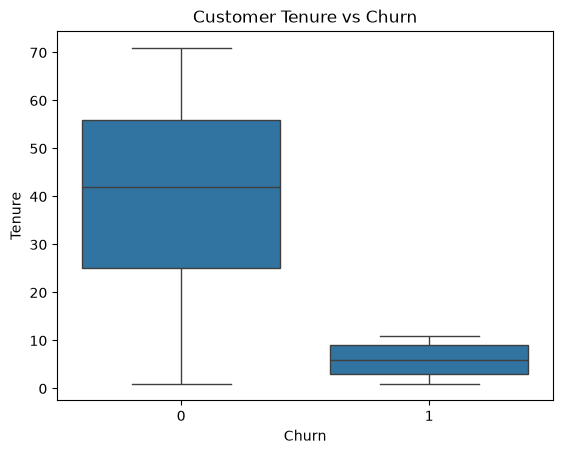

In [19]:
sns.boxplot(data=df, x="Churn",
            y="Tenure")
plt.title("Customer Tenure vs Churn")
plt.savefig("../visuals/04_tenure_churn.png",
            bbox_inches="tight")
plt.show()

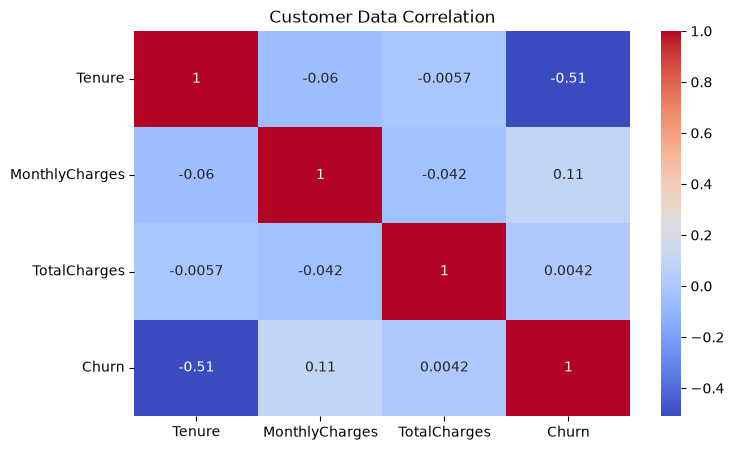

In [20]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[["Tenure", "MonthlyCharges",
        "TotalCharges", "Churn"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Customer Data Correlation")
plt.savefig("../visuals/05_correlation.png",
            bbox_inches="tight")
plt.show()